# 02 · Observation distributions

The composition of the MSHMM catalog by source category, satellite sensor, plume annotation status, and batch.  

### 1. Load the catalog

Set `DATA_ROOT` to the directory containing `db.xlsx` and the three batch folders.  
Change `DATA_ROOT` with your local data path.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebook":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from mshmm.catalog import load_catalog
from mshmm.statistics import count_records, summarize_flux
from mshmm.plotting import plot_counts

DATA_ROOT = REPO_ROOT.parent  # Change this to your data root.
catalog = load_catalog(DATA_ROOT)
print(f"Observations: {len(catalog):,}")

Observations: 1,686


### 2. Count observations by category

Compare source categories (`type`), sensors (`sensor`), emission event status (`is_plume`), and batches (`batch`).  

Observations by type


,count,percent
type,,
coal,163,9.67
oil,251,14.89
waste,1272,75.44


Observations by sensor


,count,percent
sensor,,
EMIT,690,40.93
ENMAP,194,11.51
GF5,635,37.66
PRS,167,9.91


Observations by is_plume


,count,percent
is_plume,,
False,1305,77.4
True,381,22.6


Observations by batch


,count,percent
batch,,
0,793,47.03
1,664,39.38
2,229,13.58


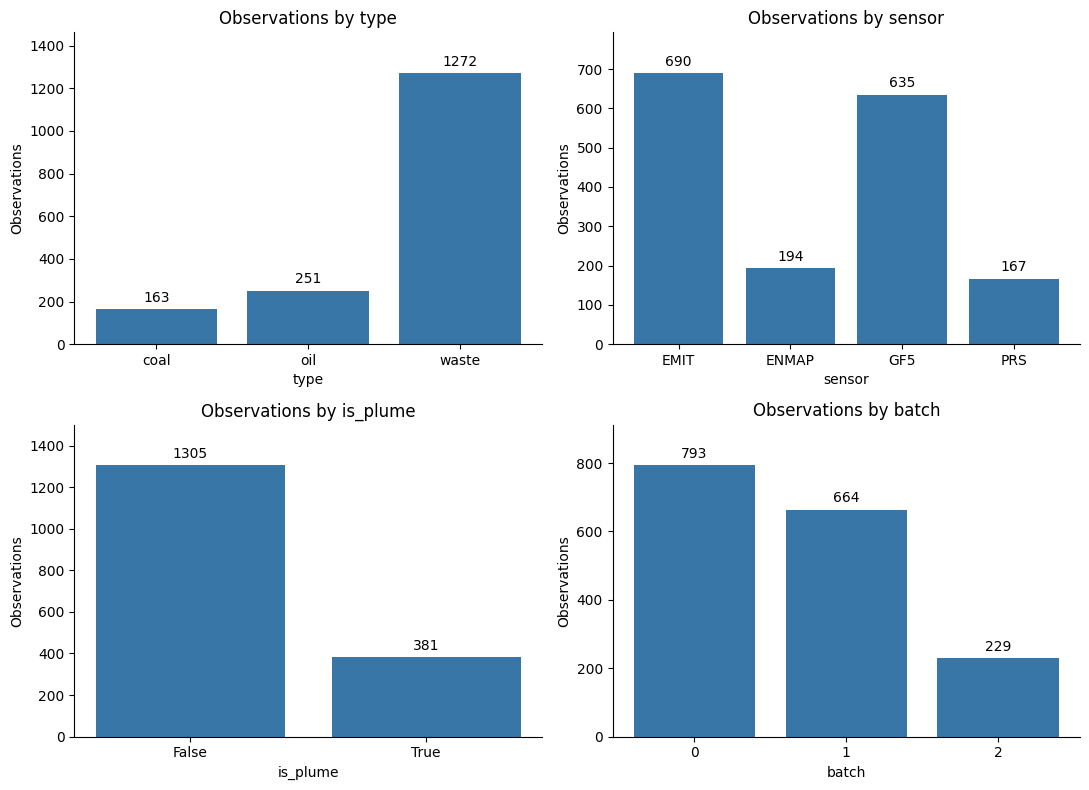

In [6]:
fields = ["type", "sensor", "is_plume", "batch"]
summaries = {field: count_records(catalog, field) for field in fields}

for field, summary in summaries.items():
    print(f"Observations by {field}")
    display(summary)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, field in zip(axes.flat, fields):
    plot_counts(summaries[field], ax=ax)
    ax.set_title(f"Observations by {field}")
fig.tight_layout()
plt.show()

### 3. Cross statistics

Compare source categories within each sensor for plume observations.  

type,coal,oil,waste
sensor,,,
EMIT,3,16,102
ENMAP,12,5,37
GF5,20,74,63
PRS,5,25,19


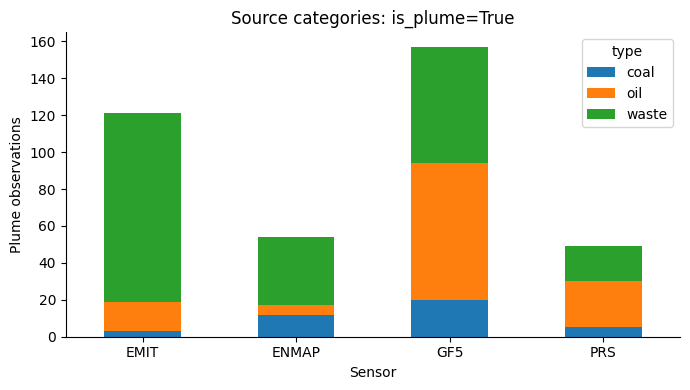

In [9]:
plumes = catalog.loc[catalog["is_plume"]]
sensor_type = pd.crosstab(plumes["sensor"], plumes["type"])

display(sensor_type)

fig, ax = plt.subplots(figsize=(7, 4))
sensor_type.plot.bar(stacked=True, ax=ax, rot=0)
ax.set_title("Source categories: is_plume=True")
ax.set_xlabel("Sensor")
ax.set_ylabel("Plume observations")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 4. Count by emission flux Q

`Q` is the estimated emission flux in kg/h. Its distribution is calculated from plume records with available `Q` values.  
Non-plume records have missing `Q` values and are excluded; `Q_err` describes flux uncertainty.

Plume records: 381
Available Q values: 381
Missing Q values among plume records: 0


,Q (kg/h)
count,381.000000
mean,4415.913386
std,5995.327999
min,117.270000
25%,1059.990000
50%,2226.600000
75%,5482.510000
max,46232.470000


Q by sensor (kg/h)


,count,mean,std,min,25%,50%,75%,max
sensor,,,,,,,,
EMIT,121.0,3793.367521,3462.851581,445.07,1437.4400,2632.86,4979.56,22379.62
ENMAP,54.0,3298.104630,4097.564301,151.74,711.9875,2116.90,3339.26,18787.97
GF5,157.0,4906.345732,7932.620375,117.27,717.3400,1944.85,5030.23,46232.47
PRS,49.0,5613.706122,5185.941928,251.53,1059.9900,4156.35,9647.36,19099.77


Q by source category (kg/h)


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
coal,40.0,4395.641750,4535.504985,238.16,835.535,2814.885,6555.315,18787.97
oil,120.0,7605.139667,8923.362591,224.47,1417.140,4195.840,11125.595,46232.47
waste,221.0,2687.875882,2611.524901,117.27,1005.690,1903.310,3124.070,13205.99


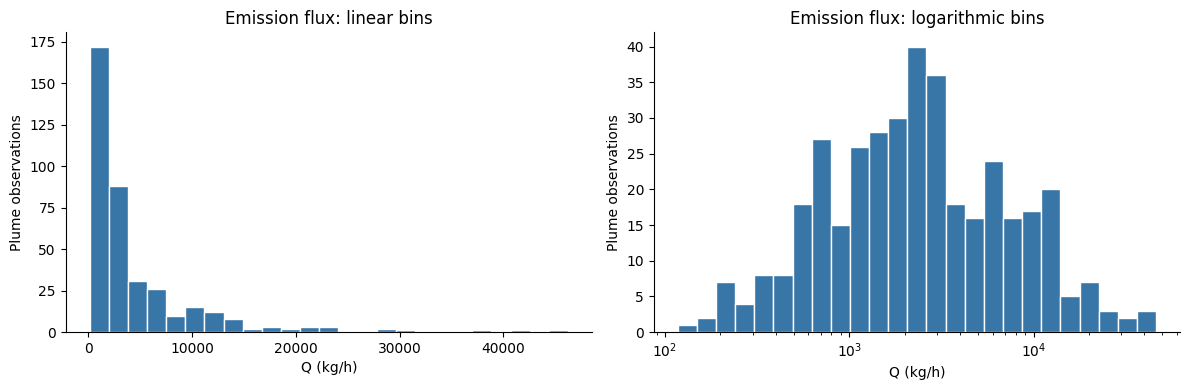

In [7]:
plumes = catalog.loc[catalog["is_plume"]]
flux = plumes["Q"].dropna()

print(f"Plume records: {len(plumes):,}")
print(f"Available Q values: {len(flux):,}")
print(f"Missing Q values among plume records: {plumes['Q'].isna().sum()}")
display(flux.describe().to_frame("Q (kg/h)"))
print("Q by sensor (kg/h)")
display(summarize_flux(catalog, "sensor"))
print("Q by source category (kg/h)")
display(summarize_flux(catalog, "type"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(flux, bins=25, color="#3976a8", edgecolor="white")
axes[0].set_title("Emission flux: linear bins")
log_bins = np.geomspace(flux.min(), flux.max(), 26)
axes[1].hist(flux, bins=log_bins, color="#3976a8", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Emission flux: logarithmic bins")
for ax in axes:
    ax.set_xlabel("Q (kg/h)")
    ax.set_ylabel("Plume observations")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()